In [1]:
%pip install -q ultralytics==8.4.1
!git clone https://github.com/mdmohsin212/WasteScope.git

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 19.1 MB/s eta 0:00:00a 0:00:01
Cloning into 'WasteScope'...
remote: Enumerating objects: 326, done.
remote: Counting objects: 100% (326/326), done.
remote: Compressing objects: 100% (170/170), done.
remote: Total 326 (delta 166), reused 276 (delta 122), pack-reused 0 (from 0)
Receiving objects: 100% (326/326), 6.91 MiB | 24.31 MiB/s, done.
Resolving deltas: 100% (166/166), done.


In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import sys
from pathlib import Path

REPO_DIR = Path("/content/WasteScope")
sys.path.insert(0, str(REPO_DIR))

In [4]:
import hashlib
import json
import shutil
import zipfile
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display
from matplotlib.patches import Rectangle
from PIL import Image
from ultralytics import YOLO
from ultralytics.data.utils import IMG_FORMATS

from src.data.annotations import read_yolo_labels
from src.data.boxes import xyxy_to_xywhn, xyxy_to_coco_xywh, xywhn_to_xyxy
from src.data.splits import SplitManifest, video_id
from src.evaluation.metrics import coco_results, detection_errors, evaluate_coco

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [5]:
REPO_DIR = Path("/content/WasteScope")
sys.path.insert(0, str(REPO_DIR))
BASE = Path("/content/drive/MyDrive/WasteScope")
RUN_NAME = "D0_yolo26n_640"

DRIVE_RUN = BASE / "runs" / "detect" / RUN_NAME
VAL_ZIP = BASE / "prepared" / "detection" / "val_v2.zip"
MANIFEST_PATH = BASE / "manifests" / "video_split.json"
DRIVE_REPORT = BASE / "reports" / "detection" / RUN_NAME / "val"

WORK = Path("/content/wastescope_analysis") / RUN_NAME
LOCAL_RUN = WORK / "training_run"
DATA = Path("/content/detection")
OUT = WORK / "validation"

REVIEW_CONF = 0.25
N_EXAMPLES = 4
OUT.mkdir(parents=True, exist_ok=True)

In [6]:
for relative in ("args.yaml", "results.csv", "weights/best.pt"):
    destination = LOCAL_RUN / relative
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(DRIVE_RUN / relative, destination)

shutil.copy2(MANIFEST_PATH, WORK / "video_split.json")
manifest = SplitManifest.from_file(WORK / "video_split.json")
names = list(manifest.classes)

ready = DATA / "val.ready"
if not ready.exists():
    DATA.mkdir(parents=True, exist_ok=True)
    local_zip = DATA / "val.zip"
    shutil.copy2(VAL_ZIP, local_zip)
    with zipfile.ZipFile(local_zip) as archive:
        archive.extractall(DATA)
    local_zip.unlink()
    ready.write_text("Extracted successfully")

image_paths = sorted(
    p for p in (DATA / "val" / "images").iterdir()
    if p.is_file() and p.suffix.lower().lstrip(".") in IMG_FORMATS
)

In [7]:
(DATA / "data.yaml").write_text(yaml.safe_dump({
    "path": str(DATA), 
    "train": "train/images", 
    "val": "val/images",
    "names": dict(enumerate(names))
}, sort_keys=False))

train_args = yaml.safe_load((LOCAL_RUN / "args.yaml").read_text())
history = pd.read_csv(LOCAL_RUN / "results.csv")
history.columns = history.columns.str.strip()
IMGSZ = int(train_args["imgsz"])
BEST = LOCAL_RUN / "weights" / "best.pt"

print("Run:", RUN_NAME)
print("Validation images:", len(image_paths))
print("Completed epochs:", int(history["epoch"].max()))
print("Evaluation image size:", IMGSZ)
print("Classes:", names)

Run: D0_yolo26n_640
Validation images: 5018
Completed epochs: 75
Evaluation image size: 640
Classes: ['container_yellow', 'container_green', 'container_default', 'container_blue', 'container_oil', 'container_battery', 'container_biodegradable']


**Inspect training history**

In [8]:
metric_columns = {
    "metrics/precision(B)": "Precision", "metrics/recall(B)": "Recall",
    "metrics/mAP50(B)": "mAP50", "metrics/mAP50-95(B)": "mAP50-95",
}
best_logged = history.loc[history["metrics/mAP50-95(B)"].idxmax()]

display(best_logged[["epoch", *metric_columns]].rename(
    index={"epoch": "Epoch", **metric_columns}
).to_frame("Best logged validation epoch").round(4))

,Best logged validation epoch
Epoch,55.0000
Precision,0.8868
Recall,0.7976
mAP50,0.8535
mAP50-95,0.6415


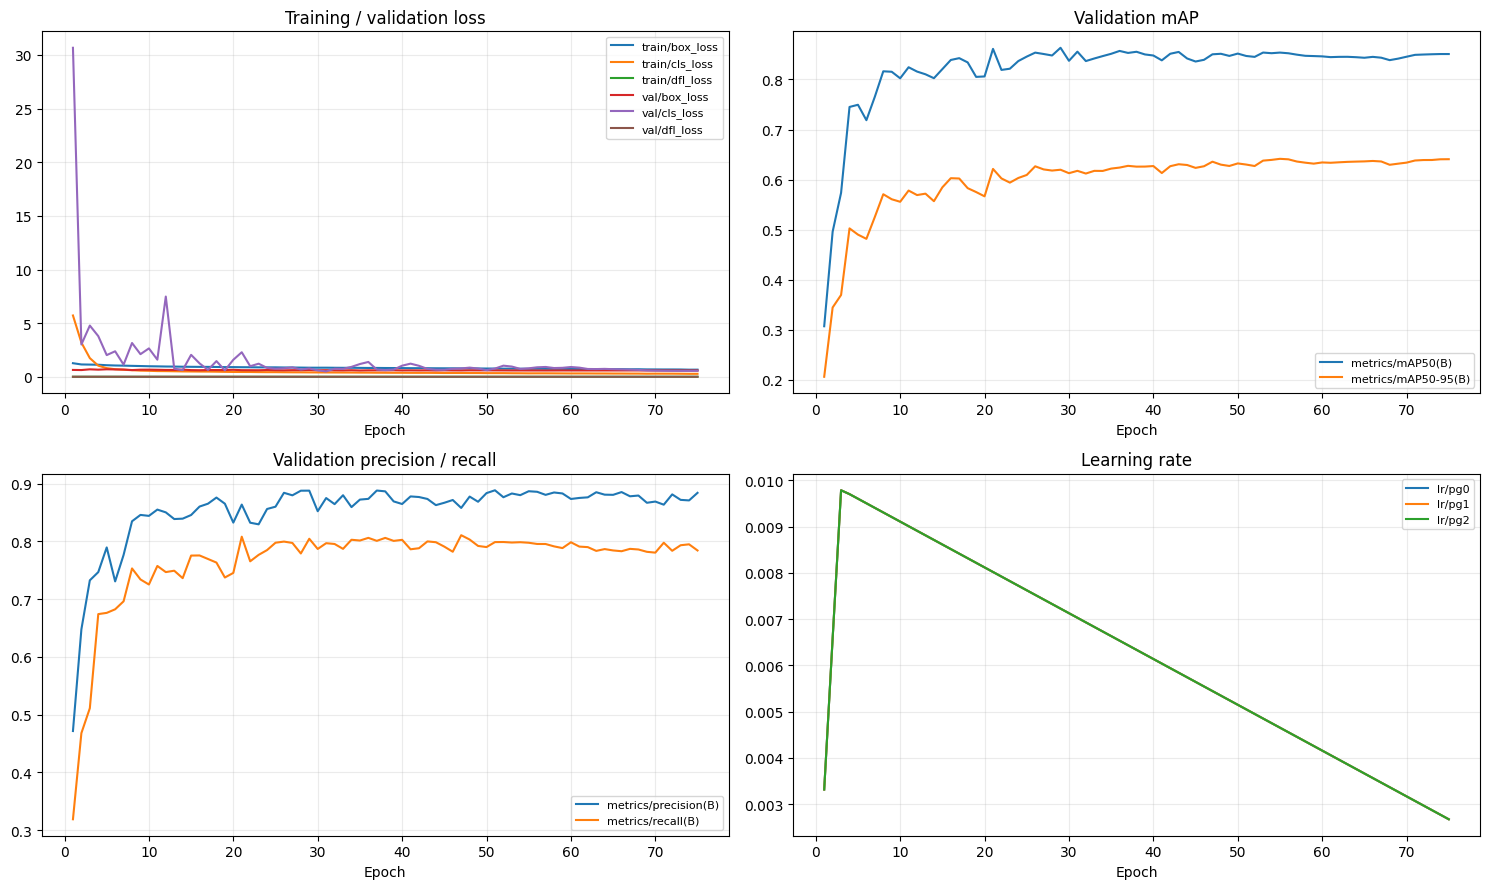

In [9]:
groups = [
    ([c for c in history if c.endswith("_loss")], "Training / validation loss"),
    (["metrics/mAP50(B)", "metrics/mAP50-95(B)"], "Validation mAP"),
    (["metrics/precision(B)", "metrics/recall(B)"], "Validation precision / recall"),
    ([c for c in history if c.startswith("lr/")], "Learning rate")
]

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, (columns, title) in zip(axes.flat, groups):
    for column in columns:
        ax.plot(history["epoch"], history[column], label=column)
    ax.set(title=title, xlabel="Epoch")
    ax.grid(alpha=0.25)
    if columns:
        ax.legend(fontsize=8)
        
fig.tight_layout()
fig.savefig(OUT / "training_curves.png", dpi=160)
plt.show()
plt.close(fig)

**Validate the best checkpoint once**

In [12]:
model = YOLO(str(BEST))
gpu_available = torch.cuda.is_available()
validation = {}

def capture_predictions(validator):
    validation.update(
        predictions=validator.jdict,
        seen=validator.seen,
        precision=16 if validator.args.half else 32
    )

model.add_callback("on_val_end", capture_predictions)

val_metrics = model.val(
    data=str(DATA / "data.yaml"), 
    split="val", 
    imgsz=IMGSZ,
    batch=16,
    device=0,
    workers=2,
    half=True,
    conf=0.001, 
    iou=0.7, 
    max_det=300,
    nms=train_args.get("nms"), 
    agnostic_nms=False,
    augment=False, 
    rect=True, 
    cache=False,
    plots=True, 
    save_json=True,
    project=str(WORK), 
    name=OUT.name, 
    exist_ok=True
)

overall = pd.DataFrame([{
    "Run": RUN_NAME, 
    "Split": "val",
    "Precision": val_metrics.box.mp, 
    "Recall": val_metrics.box.mr,
    "mAP50": val_metrics.box.map50, 
    "mAP50-95": val_metrics.box.map
}]).set_index("Run")

display(overall.round(4))

Ultralytics 8.4.1 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,376,201 parameters, 0 gradients, 5.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 133.2±31.6 MB/s, size: 2808.4 KB)
val: Scanning /content/detection/val/labels... 5018 images, 2529 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5018/5018 93.8it/s 53.5ss<0.1s
val: New cache created: /content/detection/val/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 314/314 1.3it/s 3:57<0.8s
                   all       5018      10203      0.887      0.797      0.853      0.641
      container_yellow       1351       1351      0.728      0.829      0.757      0.556
       container_green       1478       1478      0.893      0.859      0.903      0.671
     container_default       2294       4850      0.949      0.771      0.889      0.663
        container_blue       1606       1606      0.897      0.

,Split,Precision,Recall,mAP50,mAP50-95
Run,,,,,
D0_yolo26n_640,val,0.8866,0.7973,0.8533,0.6414


In [13]:
REPORT = DRIVE_REPORT
METRICS = REPORT / "metrics"
FIGURES = REPORT / "figures"
FAILURES = REPORT / "failure_cases"
for folder in (REPORT, METRICS, FIGURES, FAILURES):
    folder.mkdir(parents=True, exist_ok=True)

for path in list(OUT.rglob("*")):
    if not path.is_file():
        continue
    if path.suffix.lower() in {".png", ".jpg", ".jpeg", ".svg", ".pdf"}:
        folder = FAILURES if path.name.startswith(("val_batch", "failure_")) else FIGURES
    elif path.suffix.lower() == ".csv":
        folder = METRICS
    else:
        folder = REPORT
    target = folder / path.name
    if path.resolve() != target.resolve():
        shutil.copy2(path, target)

history.to_csv(METRICS / "training_history.csv", index=False)
best_logged[["epoch", *metric_columns]].rename(
    index={"epoch": "Epoch", **metric_columns}
).to_frame("Best logged validation epoch").to_csv(METRICS / "best_logged_validation.csv")

overall.to_csv(METRICS / "overall_ultralytics.csv")
(REPORT / "native_predictions.json").write_text(json.dumps(validation["predictions"]), encoding="utf-8")
shutil.copy2(WORK / "video_split.json", REPORT / "video_split.json")

training_environment = DRIVE_RUN / "environment.json"
configuration = {
    "run": RUN_NAME, 
    "split": "val", 
    "status": "partial",
    "checkpoint": str(DRIVE_RUN / "weights" / "best.pt"),
    "checkpoint_sha256": hashlib.sha256(BEST.read_bytes()).hexdigest(),
    "manifest_sha256": hashlib.sha256((WORK / "video_split.json").read_bytes()).hexdigest(),
    "metrics_source_sha256": hashlib.sha256((REPO_DIR / "src" / "evaluation" / "metrics.py").read_bytes()).hexdigest(),
    "validation_archive": str(VAL_ZIP),
    "classes": names, "images": len(image_paths), 
    "imgsz": IMGSZ,
    "confidence_for_ap": 0.001, 
    "nms_iou": 0.7,
    "nms": train_args.get("nms"), 
    "prediction_max_det": 300,
    "coco_max_dets": [1, 10, 100],
    "review_confidence": REVIEW_CONF, 
    "review_match_iou": 0.5,
    "precision": "FP16",
    "device": torch.cuda.get_device_name(0),
    "training_args": train_args,
    "training_environment": json.loads(training_environment.read_text()) if training_environment.is_file() else None,
    "versions": {package: version(package) for package in ("ultralytics", "torch", "pycocotools", "numpy", "pandas")}
}

def save_configuration(**updates):
    configuration.update(updates)
    (REPORT / "evaluation_config.json").write_text(json.dumps(configuration, indent=2), encoding="utf-8")

save_configuration()
print("Each following section saves directly to Drive:", REPORT)

Each following section saves directly to Drive: /content/drive/MyDrive/WasteScope/reports/detection/D0_yolo26n_640/val


**Prepare COCO ground truth and evaluate the same predictions**

In [14]:
images, annotations = [], []
filename_to_id, image_lookup = {}, {}

prepared_class_map = {index: index for index in range(len(names))}

for image_id, path in enumerate(image_paths, start=1):
    with Image.open(path) as image:
        width, height = image.size
        
    images.append({
        "id": image_id, "file_name": path.name,
        "width": width, "height": height
    })
    
    filename_to_id[path.name] = image_id
    image_lookup[image_id] = path
    labels = read_yolo_labels(
        DATA / "val" / "labels" / f"{path.stem}.txt",
        class_map=prepared_class_map
    )
    
    for label in labels:
        box = xyxy_to_coco_xywh(xywhn_to_xyxy(
            label.xywhn, width, height, clip=True
        ))
        
        annotations.append({
            "id": len(annotations) + 1, 
            "image_id": image_id,
            "category_id": label.class_id + 1,
            "bbox": list(box), 
            "area": box[2] * box[3], 
            "iscrowd": 0
        })


ground_truth = {
    "images": images, 
    "annotations": annotations,
    "categories": [{"id": i + 1, "name": name} for i, name in enumerate(names)]
}

predictions = [{
    "image_id": filename_to_id[p["file_name"]],
    "category_id": p["category_id"], 
    "bbox": p["bbox"], 
    "score": p["score"]
} for p in validation["predictions"]]

In [17]:
(REPORT / "coco_ground_truth.json").write_text(json.dumps(ground_truth), encoding="utf-8")
(REPORT / "coco_predictions.json").write_text(json.dumps(predictions), encoding="utf-8")
save_configuration(instances=len(annotations))


evaluation = evaluate_coco(ground_truth, predictions)
author_table = coco_results(evaluation)
errors = detection_errors(evaluation, confidence=REVIEW_CONF, iou=0.5)

author_table.to_csv(METRICS / "per_class_coco.csv")
errors.per_class.to_csv(METRICS / "per_class_errors.csv")
display(author_table.round(4))


class_results = author_table.drop(index="All Classes")
weak_classes = class_results.dropna(subset=["AP@[.50:.95]"]).nsmallest(3, "AP@[.50:.95]").index.tolist()

print("Classes selected for closer inspection:", ", ".join(weak_classes))

creating index...
index created!
Loading and preparing results...
DONE (t=0.02s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=3.30s).
Accumulating evaluation results...
DONE (t=0.78s).


,Instances,AP@0.50,AP@[.50:.95],AR@[.50:.95]
Class,,,,
container_yellow,1351,0.7448,0.5344,0.6942
container_green,1478,0.8867,0.6426,0.7015
container_default,4850,0.8597,0.6182,0.6809
container_blue,1606,0.8188,0.6064,0.7055
container_oil,249,0.8479,0.6408,0.7016
container_battery,461,0.7888,0.5471,0.5946
container_biodegradable,208,0.8976,0.7018,0.7587
All Classes,10203,0.8349,0.6130,0.6910


Classes selected for closer inspection: container_yellow, container_battery, container_blue


**Inspect class errors, video variation and object size**

In [18]:
image_errors = errors.per_image.copy()
image_errors["Video"] = image_errors["Image"].map(video_id)

video_results = image_errors.groupby("Video").agg(
    Images=("Image", "size"), Objects=("Objects", "sum"),
    TP=("TP", "sum"), FP=("FP", "sum"), FN=("FN", "sum")
)
video_results["Precision"] = video_results["TP"] / (video_results["TP"] + video_results["FP"]).replace(0, np.nan)

video_results["Recall"] = video_results["TP"] / (video_results["TP"] + video_results["FN"]).replace(0, np.nan)

gt = evaluation.cocoGt
dt = evaluation.cocoDt
object_rows = []

for annotation in annotations:
    image = gt.imgs[annotation["image_id"]]
    scale = IMGSZ / max(image["width"], image["height"])
    object_rows.append({
        "Class": gt.cats[annotation["category_id"]]["name"],
        "Outcome": "Detected" if annotation["id"] in errors.matched_gt_ids else "Missed",
        "Estimated short side (px)": min(annotation["bbox"][2:]) * scale,
    })
    

objects = pd.DataFrame(object_rows, columns=[
    "Class", "Outcome", "Estimated short side (px)"
])
size_results = objects.groupby(["Class", "Outcome"])[
    "Estimated short side (px)"
].agg(["count", "median"])

backgrounds = image_errors[image_errors["Objects"] == 0]
background_false_alarms = int((backgrounds["FP"] > 0).sum())

print(f"Diagnostics: confidence ≥ {REVIEW_CONF}, IoU ≥ 0.50")
display(errors.per_class.round(4))
display(video_results.sort_values("Recall").round(4))

Diagnostics: confidence ≥ 0.25, IoU ≥ 0.50


,TP,FP,FN,Precision,Recall
Class,,,,,
container_yellow,1160,524,191,0.6888,0.8586
container_green,1310,243,168,0.8435,0.8863
container_default,3849,377,1001,0.9108,0.7936
container_blue,1232,215,374,0.8514,0.7671
container_oil,205,47,44,0.8135,0.8233
container_battery,352,44,109,0.8889,0.7636
container_biodegradable,174,13,34,0.9305,0.8365


,Images,Objects,TP,FP,FN,Precision,Recall
Video,,,,,,,
0021,37,37,2,0,35,1.0000,0.0541
0075,189,793,319,207,474,0.6065,0.4023
0044,290,1067,779,60,288,0.9285,0.7301
0054,220,768,586,94,182,0.8618,0.7630
0102,160,598,474,54,124,0.8977,0.7926
0103,240,925,749,114,176,0.8679,0.8097
0069,100,100,81,0,19,1.0000,0.8100
0012,260,1432,1194,249,238,0.8274,0.8338
0116,60,110,92,6,18,0.9388,0.8364


In [19]:
display(size_results.round(2))
print("Background images with false alarms:", f"{background_false_alarms}/{len(backgrounds)}")

image_errors.to_csv(METRICS / "per_image_errors.csv")
video_results.to_csv(METRICS / "per_video.csv")
size_results.to_csv(METRICS / "object_sizes.csv")
objects.to_csv(METRICS / "object_size_details.csv", index=False)

pd.DataFrame([{
    "Background images": len(backgrounds),
    "Background images with false alarms": background_false_alarms,
    "False alarm image rate": background_false_alarms / len(backgrounds) if len(backgrounds) else np.nan,
    "Review confidence": REVIEW_CONF, 
    "Match IoU": 0.5
}]).to_csv(METRICS / "background_false_alarms.csv", index=False)

count  median
Class                   Outcome                
container_battery       Detected    352   16.82
                        Missed      109    6.00
container_biodegradable Detected    174   45.40
                        Missed       34   15.18
container_blue          Detected   1232   36.88
                        Missed      374   32.25
container_default       Detected   3849   39.78
                        Missed     1001   21.44
container_green         Detected   1310   28.09
                        Missed      168   12.89
container_oil           Detected    205   44.15
                        Missed       44   16.85
container_yellow        Detected   1160   24.72
                        Missed      191   10.39

Background images with false alarms: 12/2529


**Inspect actual failures**

In [20]:
weak_ids = {names.index(name) + 1 for name in weak_classes}

priority_images = {
    gt.anns[i]["image_id"] for i in errors.missed_gt_ids
    if gt.anns[i]["category_id"] in weak_ids
} | {
    dt.anns[i]["image_id"] for i in errors.false_positive_ids
    if dt.anns[i]["category_id"] in weak_ids
}

examples = image_errors[image_errors.index.isin(priority_images)]
if examples.empty:
    examples = image_errors[image_errors["Errors"] > 0]


def draw_box(ax, annotation, color, score=None):
    x, y, width, height = annotation["bbox"]
    label = gt.cats[annotation["category_id"]]["name"]
    if score is not None:
        label += f" {score:.2f}"

    ax.add_patch(Rectangle(
        (x, y), width, height,
        fill=False, edgecolor=color, linewidth=1.5
    ))
    ax.text(
        x, y, label, fontsize=7, color="white",
        bbox={"facecolor": color, "alpha": 0.75, "pad": 1}
    )

selected_examples = (
    examples.sort_values(
        ["Errors", "FN", "FP", "Image"],
        ascending=[False, False, False, True],
    ).drop_duplicates("Video").head(N_EXAMPLES).copy()
)

selected_examples["Figure"] = selected_examples["Image"].map(
    lambda name: f"failure_{Path(name).stem}.jpg"
)

for path in FAILURES.glob("failure_*.jpg"):
    path.unlink()

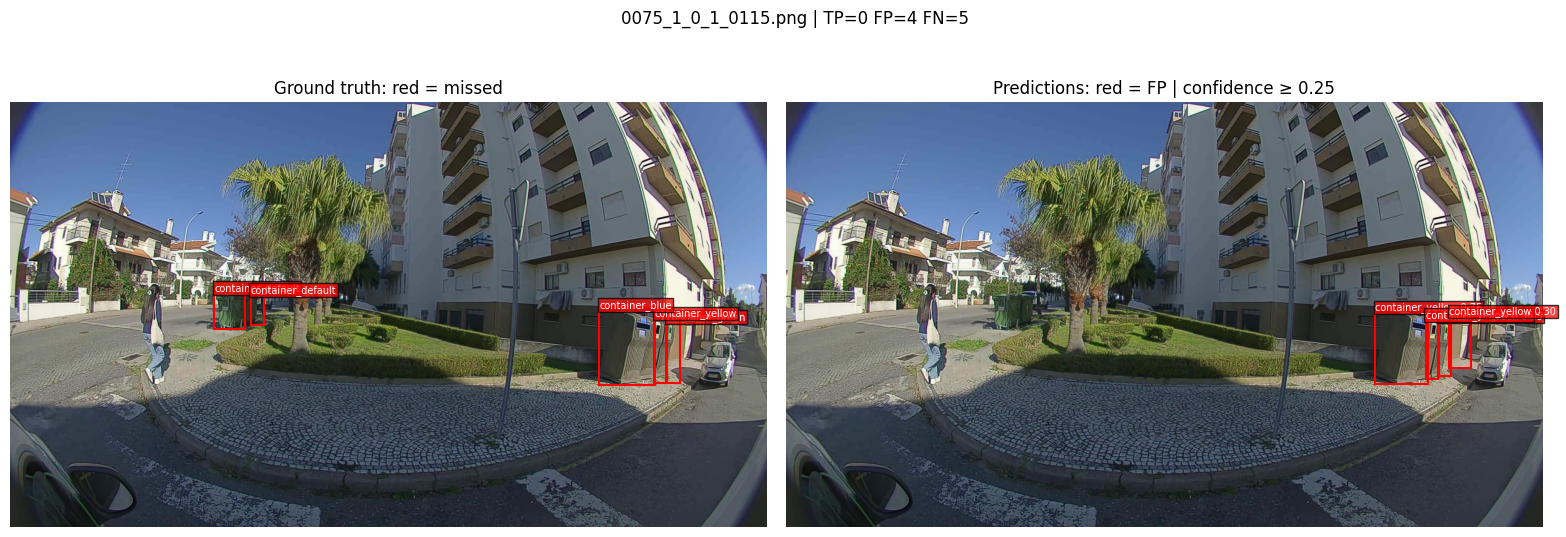

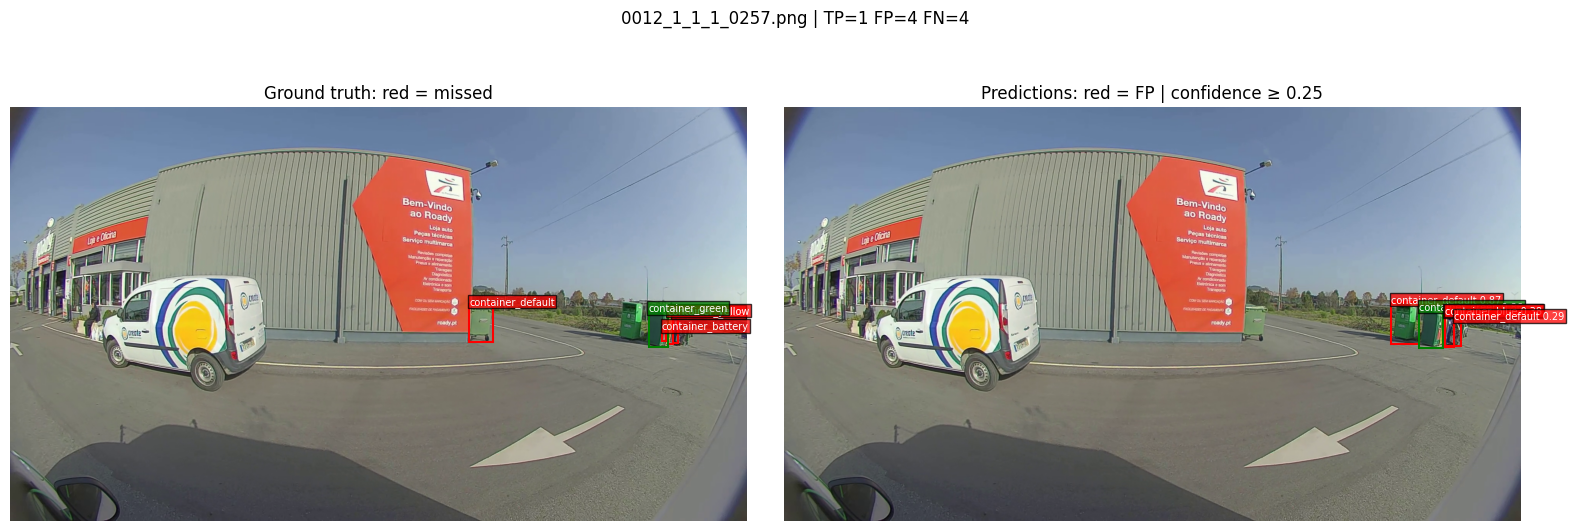

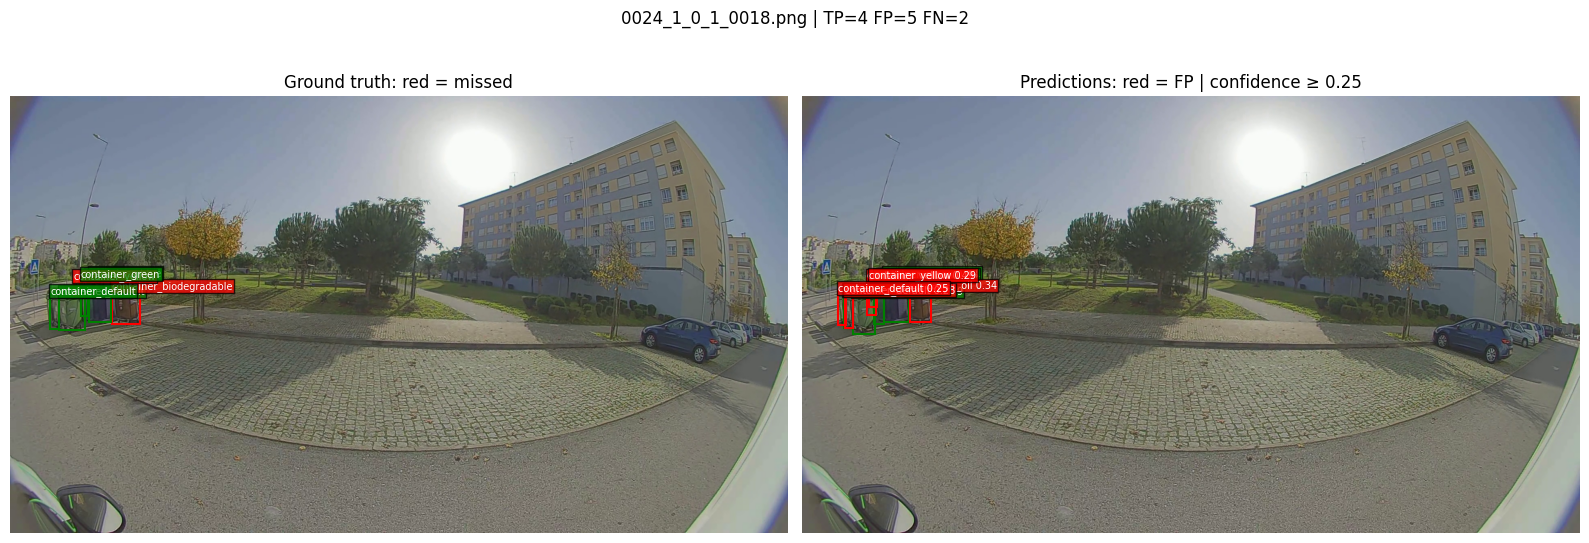

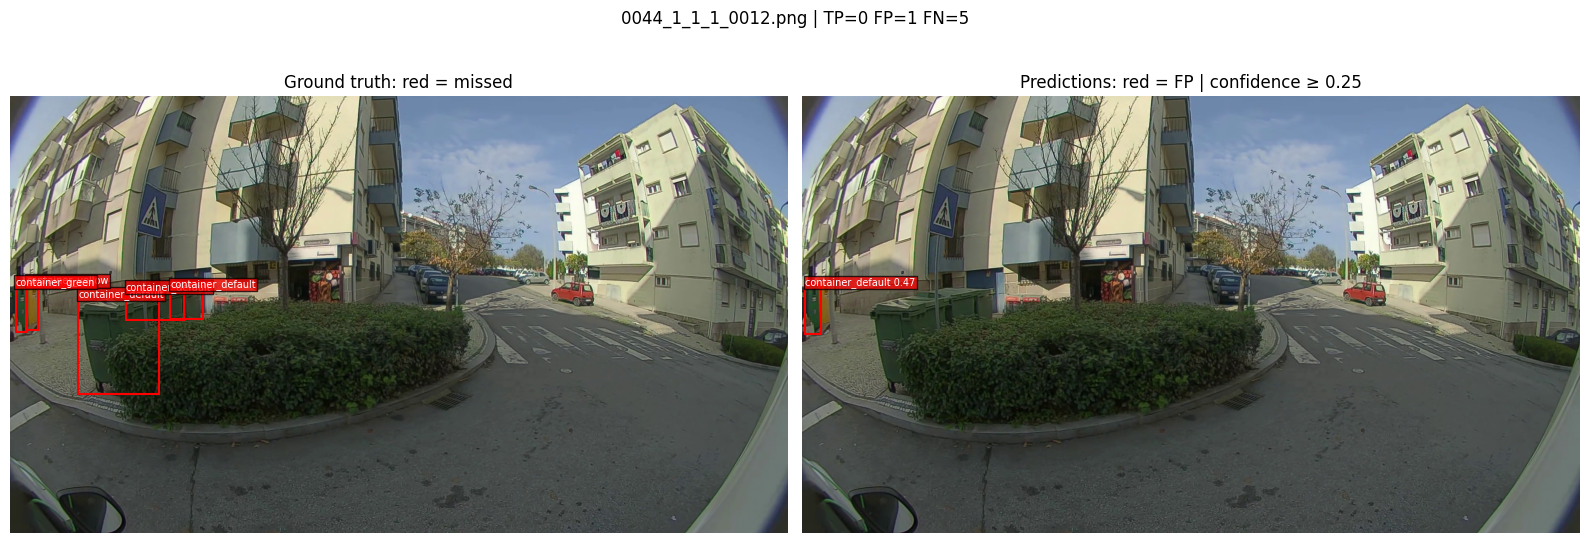

In [24]:
for image_id, row in selected_examples.iterrows():
    with Image.open(image_lookup[image_id]) as source:
        image = source.convert("RGB")
        
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for ax in axes:
        ax.imshow(image)
        ax.axis("off")
        
    for annotation in gt.imgToAnns[image_id]:
        color = "red" if annotation["id"] in errors.missed_gt_ids else "green"
        draw_box(axes[0], annotation, color)
        
    for annotation in dt.imgToAnns[image_id]:
        if annotation["id"] in errors.reviewed_prediction_ids:
            color = "red" if annotation["id"] in errors.false_positive_ids else "green"
            draw_box(axes[1], annotation, color, annotation["score"])
            
    axes[0].set_title("Ground truth: red = missed")
    axes[1].set_title(f"Predictions: red = FP | confidence ≥ {REVIEW_CONF}")
    fig.suptitle(f"{row['Image']} | TP={row['TP']} FP={row['FP']} FN={row['FN']}")
    fig.tight_layout()
    fig.savefig(FAILURES / f"failure_{Path(row['Image']).stem}.jpg", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

selected_examples.to_csv(METRICS / "failure_examples.csv")
    
if examples.empty:
    print("No FP/FN examples at this review threshold.")

In [22]:
def number(value):
    return f"{value:.2f}" if pd.notna(value) else "N/A"

weak_summary = "; ".join(
    f"{name}: {class_results.loc[name, 'AP@[.50:.95]']:.3f}"
    for name in weak_classes
)
ap_gap = (class_results["AP@0.50"] - class_results["AP@[.50:.95]"]).dropna()
gap_class = ap_gap.idxmax() if not ap_gap.empty else None
size_medians = objects.groupby("Outcome")["Estimated short side (px)"].median()
video_recall = video_results.loc[video_results["Objects"] > 0, "Recall"].dropna()

background_rate = (background_false_alarms / len(backgrounds)if len(backgrounds) else np.nan)

next_experiment_evidence = pd.DataFrame([
    (
        "Weak classes", weak_summary or "N/A", "Inspect FP/FN examples."
    ),
    (
        "Object size", f"Missed: {number(size_medians.get('Missed', np.nan))} px; "
        f"detected: {number(size_medians.get('Detected', np.nan))} px", "Compare sizes within each class."
    ),
    (
        "Localization",
        f"{gap_class}: gap={number(ap_gap.max())}" if gap_class else "N/A", "Inspect box alignment."
    ),
    (
        "Background false alarms", f"{background_false_alarms}/{len(backgrounds)}; "
        f"rate={number(background_rate)}", "Review false detections."
    ),
    (
        "Video variation",
        f"Recall: {number(video_recall.min())}–{number(video_recall.max())}", "Review low-recall videos."
    )
], columns=["Area", "Observed evidence", "Next investigation"])

next_experiment_evidence.loc[
    next_experiment_evidence["Area"].eq("Background false alarms"),
    "Observed evidence",
] = (
    f"{background_false_alarms}/{len(backgrounds)} images; "
    f"rate={background_rate:.2%}"
)

display(next_experiment_evidence)
next_experiment_evidence.to_csv(METRICS / "next_experiment_evidence.csv", index=False)

,Area,Observed evidence,Next investigation
0,Weak classes,container_yellow: 0.534; container_battery: 0....,Inspect FP/FN examples.
1,Object size,Missed: 19.52 px; detected: 33.42 px,Compare sizes within each class.
2,Localization,container_green: gap=0.24,Inspect box alignment.
3,Background false alarms,12/2529 images; rate=0.47%,Review false detections.
4,Video variation,Recall: 0.05–0.97,Review low-recall videos.


In [23]:
def markdown_table(frame):
    table = frame.reset_index()
    lines = [
        "| " + " | ".join(map(str, table.columns)) + " |",
        "| " + " | ".join(["---"] * len(table.columns)) + " |",
    ]
    for row in table.itertuples(index=False, name=None):
        cells = [
            "N/A" if pd.isna(value)
            else f"{value:.4f}" if isinstance(value, (float, np.floating))
            else str(value)
            for value in row
        ]
        lines.append(
            "| " + " | ".join(
                value.replace("|", r"\|").replace("\n", " ")
                for value in cells
            ) + " |"
        )
    return "\n".join(lines)


model_name = Path(str(train_args.get("model", "Unknown"))).name

figure_links = "\n".join(
    f"- [{path.name}](figures/{path.name})"
    for path in sorted(FIGURES.iterdir())
    if path.is_file()
)

failure_links = "\n".join(
    f"- [{row['Image']}](failure_cases/{row['Figure']})"
    for _, row in selected_examples.iterrows()
) or "No selected failures."

readme = f"""# {RUN_NAME} — validation

Model: `{model_name}` | Image size: {IMGSZ}
Epochs: {int(history['epoch'].max())}
Images: {len(images)} | Instances: {len(annotations)}

## Overall metrics — Ultralytics

{markdown_table(overall)}

## Per-class COCO AP/AR

{markdown_table(author_table)}

## Next investigation

{markdown_table(next_experiment_evidence.set_index('Area'))}

## Evaluation protocol

- Ultralytics: {version("ultralytics")}.
- Evaluated checkpoint: `best.pt`; split: validation.
- AP predictions: confidence ≥ 0.001.
- Native confusion matrix: confidence > 0.25, matching IoU > 0.45;
  class-agnostic IoU matching.
- Error CSV and failure gallery: confidence ≥ {REVIEW_CONF},
  matching IoU ≥ 0.50; COCO class-aware, score-ordered matching.
- COCO AP/AR: IoU 0.50:0.05:0.95, maxDets=[1,10,100].
- Results are from one run; no mean ± std is reported.

Confusion-matrix counts and error-CSV counts use different matching protocols.
Ultralytics and COCO AP use separate implementations.

## Figures

{figure_links}

## Selected failure examples

{failure_links}
"""

(REPORT / "README.md").write_text(readme, encoding="utf-8")

task_report = REPORT.parent.parent
comparison_path = task_report / "comparison.csv"

comparison = overall.reset_index().rename(
    columns={"mAP50–95": "mAP50-95"}
).assign(
    Model=model_name,
    ImgSize=IMGSZ,
    ManifestSHA256=configuration["manifest_sha256"],
    Evaluator=configuration["versions"]["ultralytics"]
)

if comparison_path.is_file():
    previous = pd.read_csv(comparison_path).rename(
        columns={"mAP50–95": "mAP50-95"}
    )
    comparison = pd.concat(
        [previous, comparison], ignore_index=True
    )

comparison = comparison.drop_duplicates(
    ["Run", "Split"], keep="last"
).sort_values(["Run", "Split"])

comparison.to_csv(comparison_path, index=False)
report_links = "\n".join(
    f"- [{item.Run} / {item.Split}]({item.Run}/{item.Split}/README.md)"
    for item in comparison.itertuples(index=False)
)

comparison_view = comparison.drop(
    columns=["ManifestSHA256"]
).set_index("Run")

(task_report / "comparison.md").write_text(
    "# Detection comparison\n\n"
    + markdown_table(comparison_view)
    + "\n\n" + report_links + "\n",
    encoding="utf-8"
)

save_configuration(
    status="complete",
    confusion_matrix={
        "confidence": 0.25,
        "match_iou": 0.45,
        "matching": "class-agnostic, IoU-priority"
    },
    error_review={
        "confidence": REVIEW_CONF,
        "match_iou": 0.50,
        "matching": "COCO class-aware, score-ordered"
    },
)

print("Reports:", REPORT)
print("Comparison:", comparison_path)

Reports: /content/drive/MyDrive/WasteScope/reports/detection/D0_yolo26n_640/val
Comparison: /content/drive/MyDrive/WasteScope/reports/detection/comparison.csv
